# Lightsheet PSFs

This is an example of using the `psfmodels.tot_psf()` function to simulate the total system PSF (excitation x detection) that would be observed on a light sheet microscope (currently, with strictly orthogonal illumination and detection).  PSFs can be simulated using `psfmodels.vectorial_psf`, `psfmodels.scalar_psf` or the scalar model from [MicroscPSF-Py](https://github.com/MicroscPSF/MicroscPSF-Py) `gLXYZFocalScan`, by setting the `psf_func` argument.  It allows for simulating offsets between in the sheet and the detection plane in Z (`z_offset`) – such as might be observed with a defocused lightsheet – as well as misalignment along the propogration direction of the sheet (`x_offset`), such as might be observed with a point source on the periphery of the field of view.

In [1]:
import psfmodels as psfm
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm

try:
    import microscPSF.microscPSF as msPSF
except ImportError:
    # !pip install MicroscPSF-Py
    print('Could not import MicroscPSF-Py, run or uncomment "!pip install MicroscPSF-Py" to install')
    raise


# simulating a basic light sheet PSF

Wavelength: 647/700nm
Ex NA: 0.025; Em NA: 0.4
Defocus: 0 microns



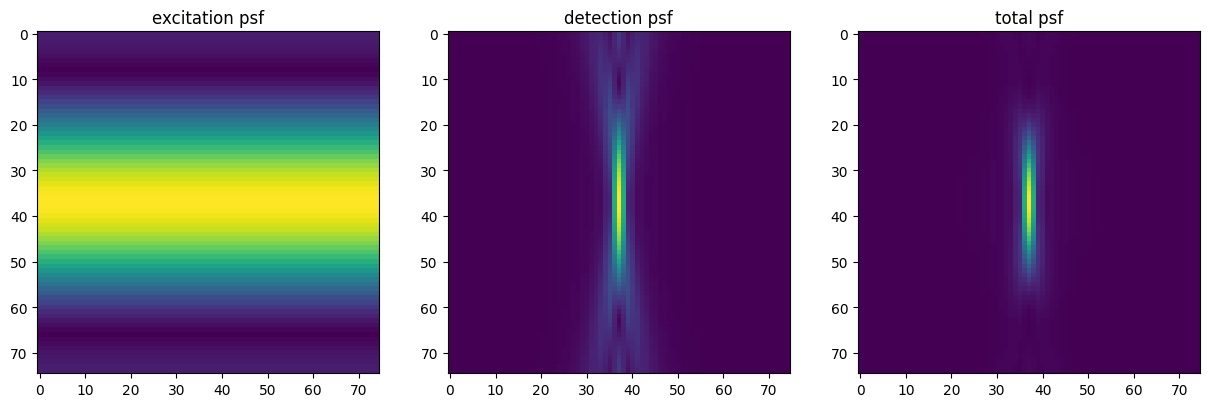

In [2]:
water_lens = {
    'ni0': 1.56, # immersion medium RI design value
    'ni': 1.56,  # immersion medium RI experimental value
    'ns': 1.56,  # specimen refractive index
    'tg': 0, # microns, coverslip thickness
    'tg0': 0 # microns, coverslip thickness design value
}
ex_lens = {**water_lens, 'NA': 0.025}
ex_wvl = 0.647
em_lens = {**water_lens, 'NA': 0.4}
em_wvl = 0.700

dxy = 0.512
dz = dxy
nx = 75
nz = 75
# mismatch between the focal point of the excitation beam
# and the point source, along the propogation direction
# of the excitation beam
x_offset = 0

# mismatch between the axial position of the excitation
# and the detection plane, with respect to the detection lens
z_offset = 0

# The psf model to use
# can be any of {'vectorial', 'scalar', or 'microscpsf'}
func = 'vectorial'

# the main function
ex_psf, em_psf, tot_psf = psfm.tot_psf(nx=nx, nz=nz, dxy=dxy, dz=dz, pz=0,
                                       x_offset=x_offset, z_offset=z_offset,
                                       ex_wvl = ex_wvl, em_wvl = em_wvl,
                                       ex_params=ex_lens, em_params=em_lens,
                                       psf_func=func)

fig, (a1,a2,a3) = plt.subplots(1,3, figsize=(15,7))
a1.imshow(ex_psf, norm=PowerNorm(gamma=0.6))
a2.imshow(em_psf[:, nx//2], norm=PowerNorm(gamma=0.6))
a3.imshow(tot_psf[:, nx//2], norm=PowerNorm(gamma=0.6))
a1.set_title('excitation psf')
a2.set_title('detection psf')
a3.set_title('total psf')
print(f"Wavelength: {int(ex_wvl*1000)}/{int(em_wvl*1000)}nm")
print(f"Ex NA: {ex_lens['NA']}; Em NA: {em_lens['NA']}")
print(f"Defocus: {z_offset} microns\n")

In [14]:

import tifffile
from scipy.ndimage import rotate

psf1 = rotate(tot_psf,-45,axes = (0,2), reshape = False)
tifffile.imwrite('psfr1.tiff',psf1)

psf2 = rotate(tot_psf,45,axes = (0,2), reshape = False)
tifffile.imwrite('psfr2.tiff',psf2)


In [4]:
tot_psf.shape
tifffile.imwrite('psf.tiff',tot_psf)

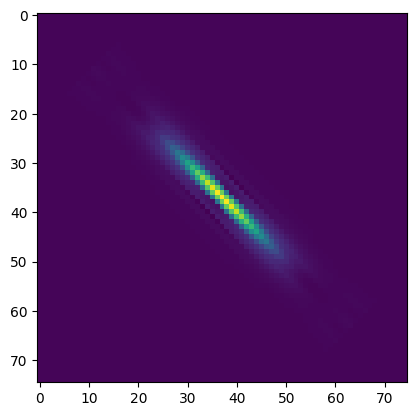

In [5]:
plt.imshow(psf[:, nx//2], norm=PowerNorm(gamma=0.6))

## simulate varying combinations of sheet defocus and misalignment

C:\Users\P70089795\AppData\Local\Temp\ipykernel_5632\4178431252.py:8: UserWarning: Not Implemented: z_offset must be an even multiple of dz. Coercing z_offset to nearest dz multiple: 2.048
  _, _, tot = psfm.tot_psf(nx=nx, nz=nz, dxy=dxy, dz=dz, pz=0,
C:\Users\P70089795\AppData\Local\Temp\ipykernel_5632\4178431252.py:8: UserWarning: Not Implemented: z_offset must be an even multiple of dz. Coercing z_offset to nearest dz multiple: 5.12
  _, _, tot = psfm.tot_psf(nx=nx, nz=nz, dxy=dxy, dz=dz, pz=0,
C:\Users\P70089795\AppData\Local\Temp\ipykernel_5632\4178431252.py:8: UserWarning: Not Implemented: z_offset must be an even multiple of dz. Coercing z_offset to nearest dz multiple: 10.24
  _, _, tot = psfm.tot_psf(nx=nx, nz=nz, dxy=dxy, dz=dz, pz=0,
C:\Users\P70089795\AppData\Local\Temp\ipykernel_5632\4178431252.py:8: UserWarning: Not Implemented: z_offset must be an even multiple of dz. Coercing z_offset to nearest dz multiple: 14.848
  _, _, tot = psfm.tot_psf(nx=nx, nz=nz, dxy=dxy, dz=dz

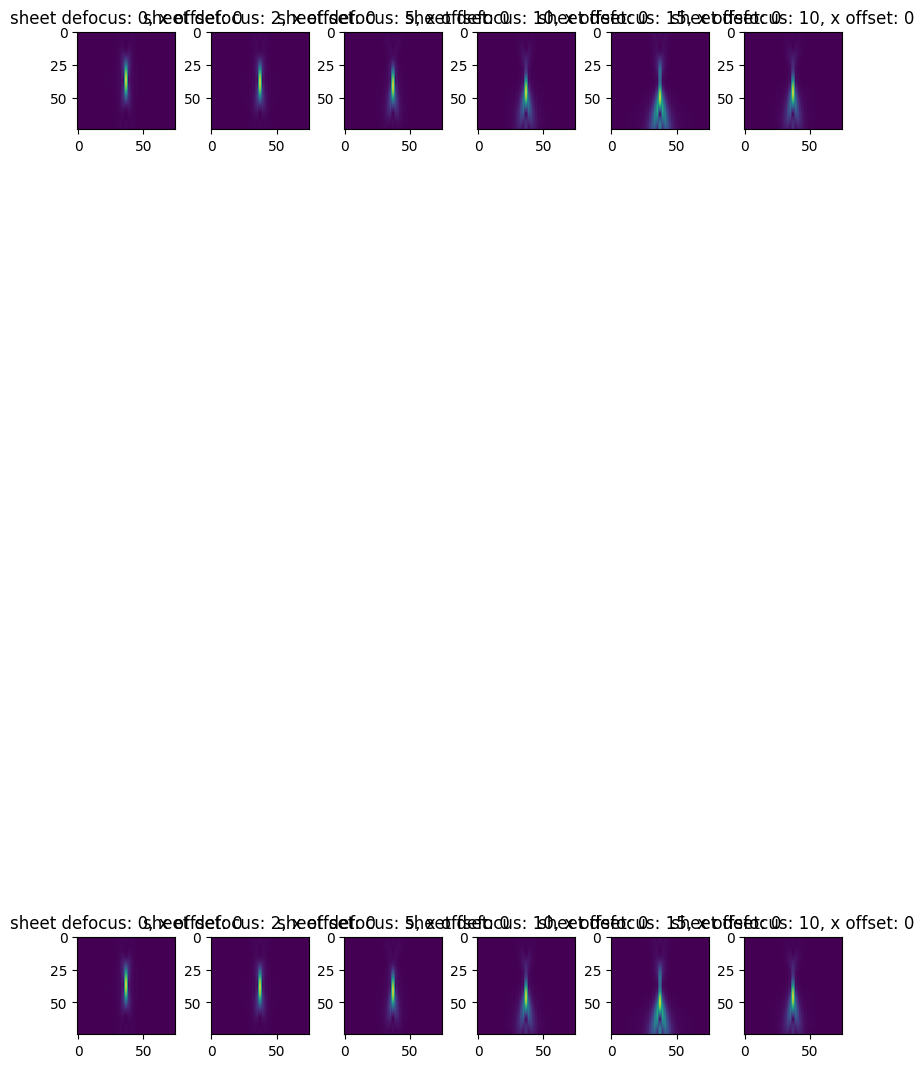

In [6]:
func = 'microscpsf'  # since it's much faster ...
zos = [0, 2, 5, 10, 15,10]
xos = [0,0]
out = np.empty((len(zos), len(xos), nz ,nx))
fig, axs = plt.subplots(len(xos), len(zos), figsize=(len(xos)*4, len(zos)*3), constrained_layout=True)
for z, zo in enumerate(zos):
    for x, xo in enumerate(xos):
        _, _, tot = psfm.tot_psf(nx=nx, nz=nz, dxy=dxy, dz=dz, pz=0,
                                       x_offset=xo, z_offset=zo,
                                       ex_wvl = ex_wvl, em_wvl = em_wvl,
                                       ex_params=ex_lens, em_params=em_lens,
                                       psf_func=func)
        axs[x, z].imshow(tot[:, nx//2], norm=PowerNorm(gamma=0.6))
        axs[x, z].set_title(f"sheet defocus: {zo}, x offset: {xo}")


In [ ]:
# from my quantification script, 2025 02 27 acquisition

In [15]:
umperpx = dxy * np.sqrt(2)


from scipy.optimize import curve_fit
from scipy.signal import peak_widths

def gauss(x, a, mu, sigma, b):
    return a*np.exp(-(x-mu)**2/(2*sigma**2))+b

def fit(yRaw,scale):
    y = yRaw - (yRaw[0]+yRaw[-1])/2
    x = (np.array(range(y.shape[0])) - y.shape[0]/2)
    x = (np.array(range(y.shape[0])) - y.shape[0]/2)
    try:
        popt, pcov = curve_fit(gauss, x, y, p0 = [1, 0, 1, 0])
        FWHM = 2.3548*popt[2]/scale
        yFit = gauss(x, *popt)
    except:
        yFit, FWHM = None, None
    return x, y, yFit, FWHM

In [20]:
def plot_psf(vol, umperpx, doplot = False):
    if doplot:
        fig, axs = plt.subplots(1,3, dpi = 300)    
        axs[0].imshow(np.max(vol, axis=0), cmap='gray')
        axs[1].imshow(np.max(vol, axis=1), cmap='gray')
        axs[2].imshow(np.max(vol, axis=2), cmap='gray')
        
        axs[1].set_title("Max proj psf")
        plt.show()


        half = vol.shape[0]//2
        plt.imshow(vol[:,half,:], cmap = 'gray')
        plt.show()
        
        fig, axs = plt.subplots(2,1, dpi = 300)    

    lateral = np.diagonal(np.fliplr(vol[:,half,:]),offset = 0, axis1 = 0, axis2 = 1)
    axial = np.diagonal(vol[:,half,:],offset = 0, axis1 = 0, axis2 = 1)



    fwhm = peak_widths(axial, [np.argmax(axial)])
    resaxial = fwhm[0]*umperpx 
    x,ya,yFita,fitresaxial = fit(axial,1/umperpx)
    


    fwhm = peak_widths(lateral, [np.argmax(lateral)])
    reslateral = fwhm[0]*umperpx 
    x,yl,yFitl,fitreslateral = fit(lateral,1/umperpx)
    if doplot:
        axs[0].plot(ya, c = 'b')
        axs[0].plot(yFita, c = 'r')
        axs[1].plot(yl, c = 'b')
        axs[1].plot(yFitl, c = 'r')
        plt.show()

    print("raw peak width {} {}".format(resaxial,reslateral))
    print("Gauss fit fwhm {} {}".format(fitresaxial,fitreslateral))
    return 

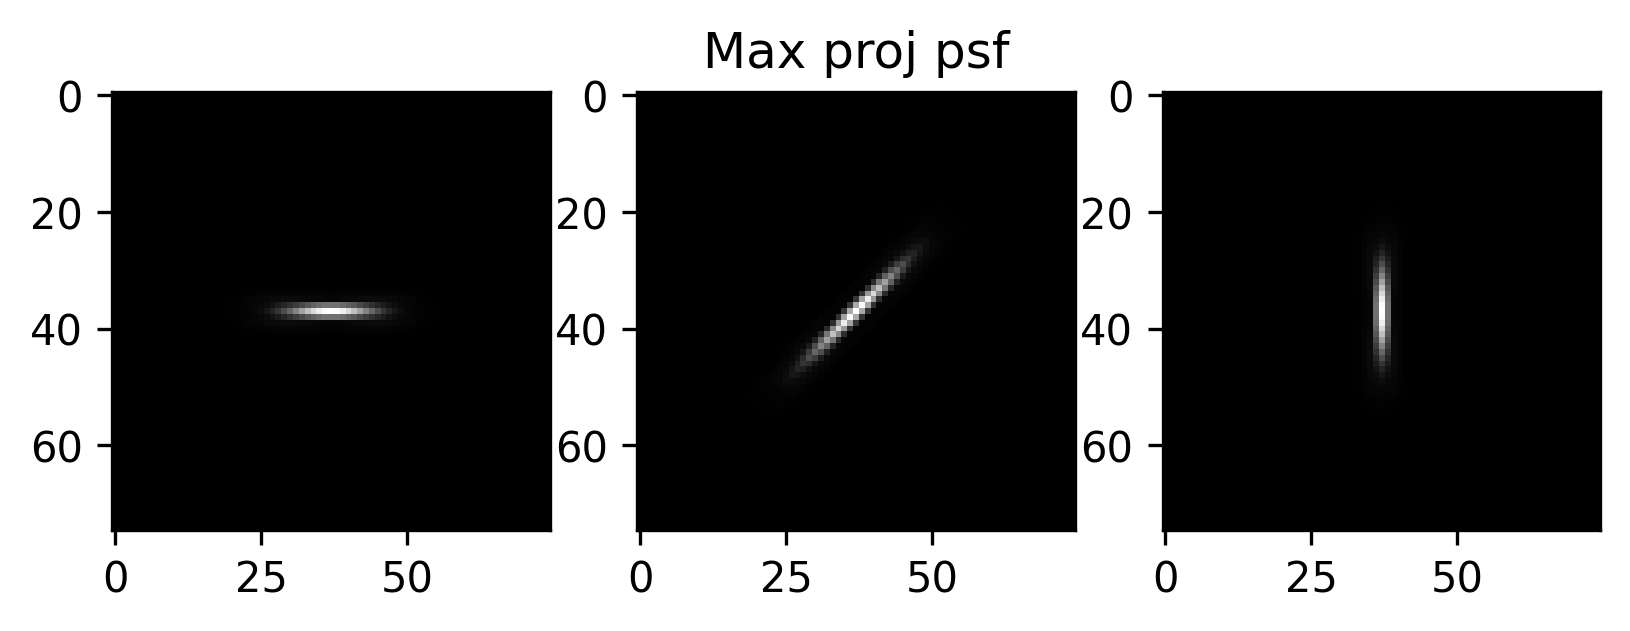

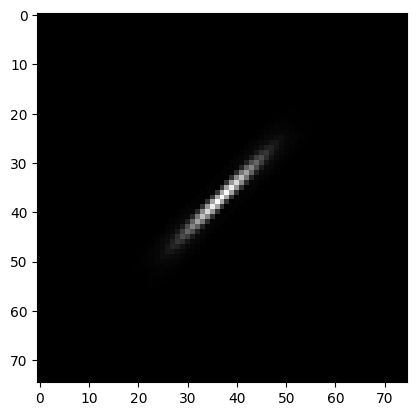

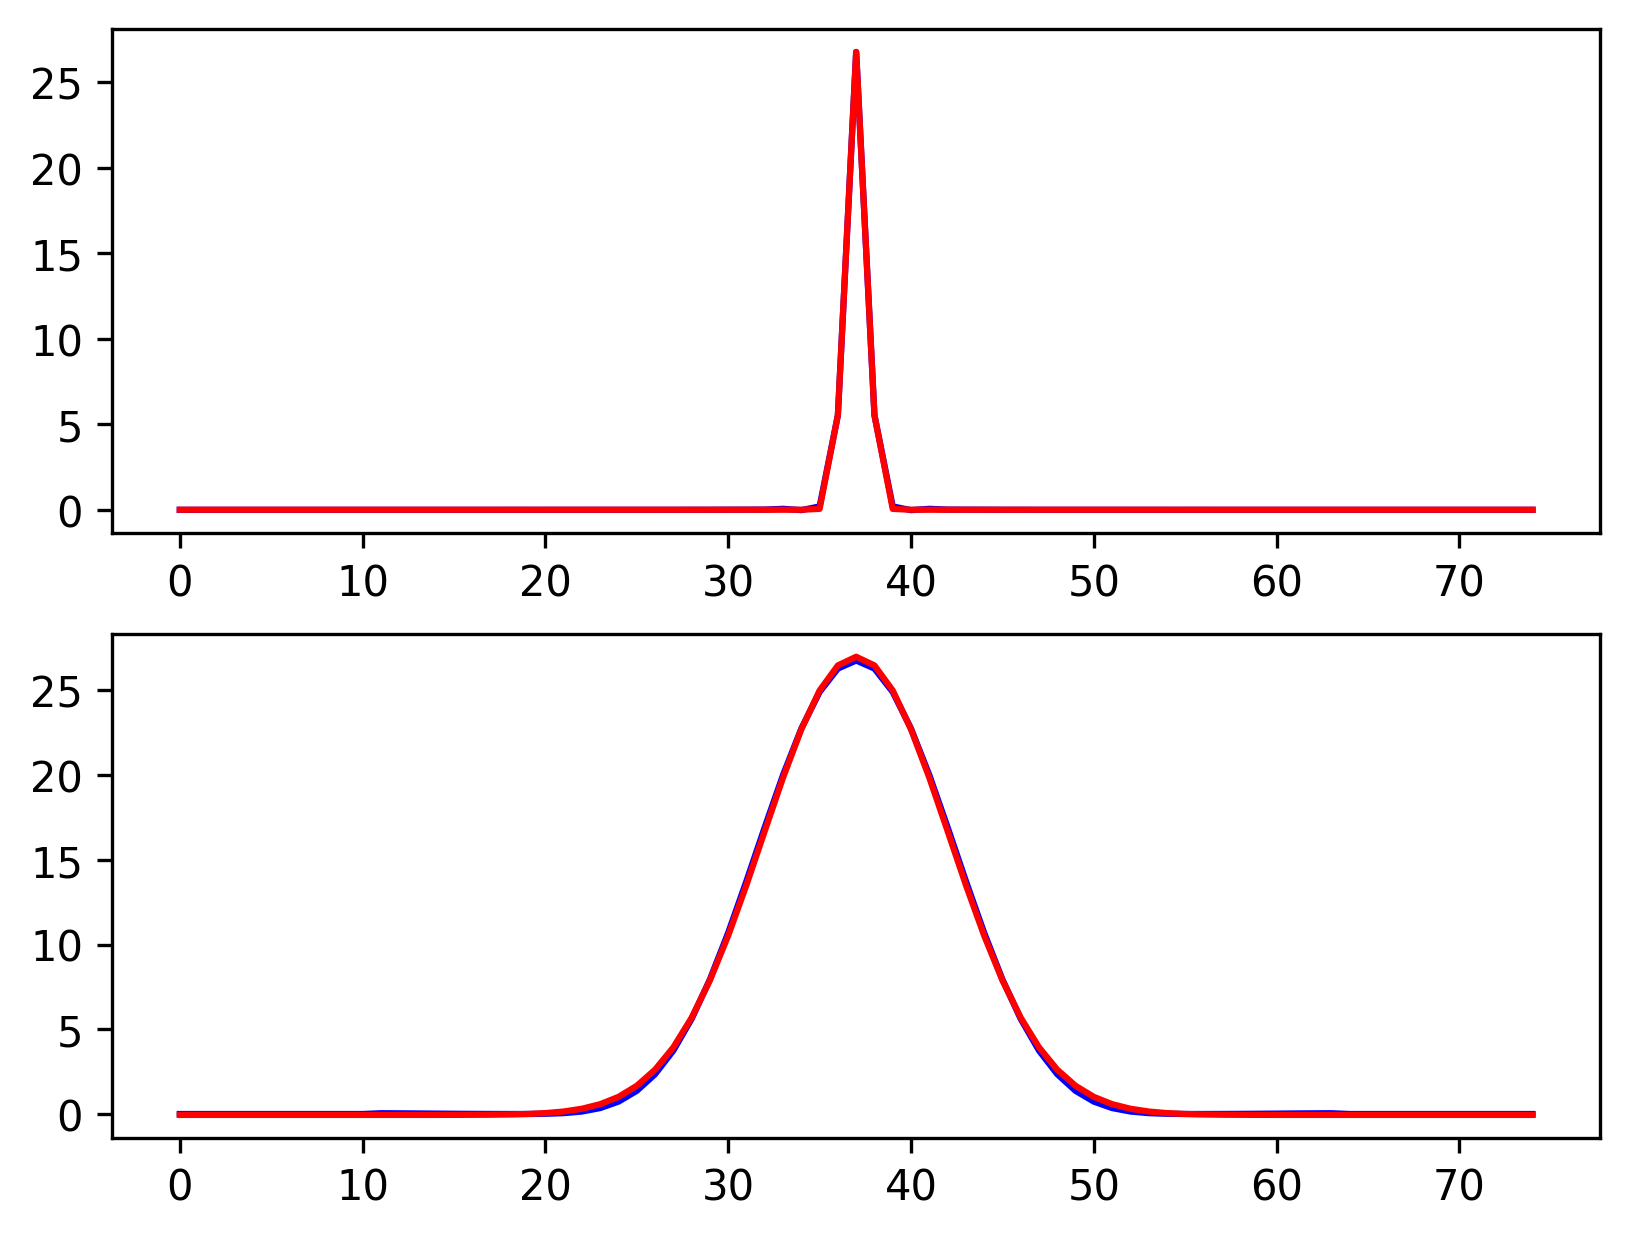

raw peak width [0.91328329] [8.86531878]
Gauss fit fwhm 0.9602233043376855 8.715599905259165


In [21]:
plot_psf(psf1,umperpx, doplot = True)